In [1]:
import numpy as np

In [2]:
!pip install -e . --user

Obtaining file:///eos/home-i00/t/tprebiba/Shared/SPS-supercycles_forNikos
  Preparing metadata (setup.py) ... done
  Running setup.py develop for supercycles


In [3]:
from supercycles.database import SPSCYCLES, PSCYCLES
from supercycles.supercycle import Supercycle

In [4]:
import matplotlib.pyplot as plt

# Supercycle table

In [5]:
SPSCYCLES.keys()

dict_keys(['SFTPRO', 'SFTPRO (9.6s)', 'LHC filling', 'LHC pilot', 'MD dedicated', 'MD parallel', 'AWAKE', 'HIRADMT1', 'HIRADMT2', 'Scrubbing', 'Zero', 'deGauss', 'deGauss (10.8s)', 'SHiP', 'SFTION1', 'SFTION2', 'LHCION_4inj', 'LHCION_pilot', 'LHCION_4inj_nom', 'LHCION_14inj_slip_stacking'])

In [12]:
AWAKE_SC = Supercycle('SPS', 'AWAKE',
                     [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['AWAKE'], SPSCYCLES['deGauss (10.8s)']])

AWAKE_parallel_MD_SC = Supercycle('SPS', 'AWAKE with parallel MD',
                                 [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['AWAKE'], SPSCYCLES['Zero'], SPSCYCLES['Zero'], SPSCYCLES['Zero'], SPSCYCLES['MD parallel']])

Dedicated_MD_SC = Supercycle('SPS', 'Dedicated MD',
                             [SPSCYCLES['MD dedicated']])

HiRadMat_SC = Supercycle('SPS', 'HiRadMat',
                         [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['HIRADMT1'], SPSCYCLES['deGauss (10.8s)']])

LHC_filling_SC = Supercycle('SPS', 'LHC filling',
                            [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['LHC filling'], SPSCYCLES['deGauss (10.8s)']])

LHC_setup_SC = Supercycle('SPS', 'LHC setup',
                          [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['LHC pilot'], SPSCYCLES['deGauss (10.8s)']])

Physics_SC = Supercycle('SPS', 'Physics',
                        [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['deGauss (10.8s)'], SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['deGauss (10.8s)'], SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['deGauss (10.8s)']])

Physics_parallel_MD_SC = Supercycle('SPS', 'Physics with parallel MD',
                                    [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['Zero'], SPSCYCLES['Zero'], SPSCYCLES['Zero'], SPSCYCLES['MD parallel']])

Scrubbing_SC = Supercycle('SPS', 'Scrubbing',
                          [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['Scrubbing'], SPSCYCLES['deGauss (10.8s)']])

Thursday_MD_SC = Supercycle('SPS', 'Thursday MD',
                            [SPSCYCLES['SFTPRO (9.6s)'], SPSCYCLES['MD dedicated'], SPSCYCLES['deGauss (10.8s)']])

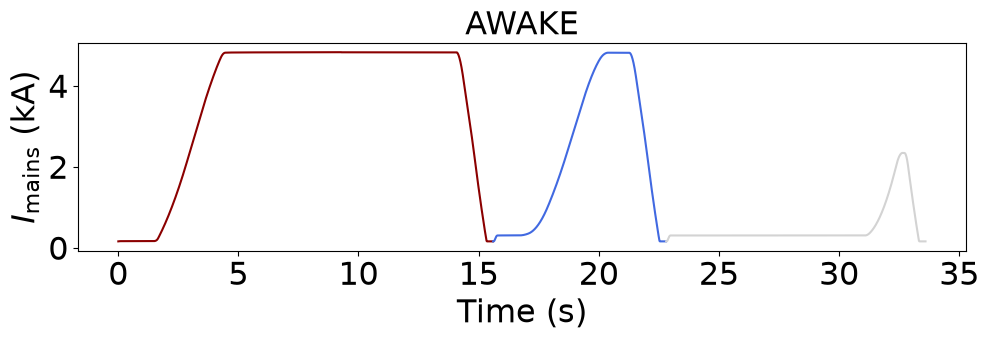

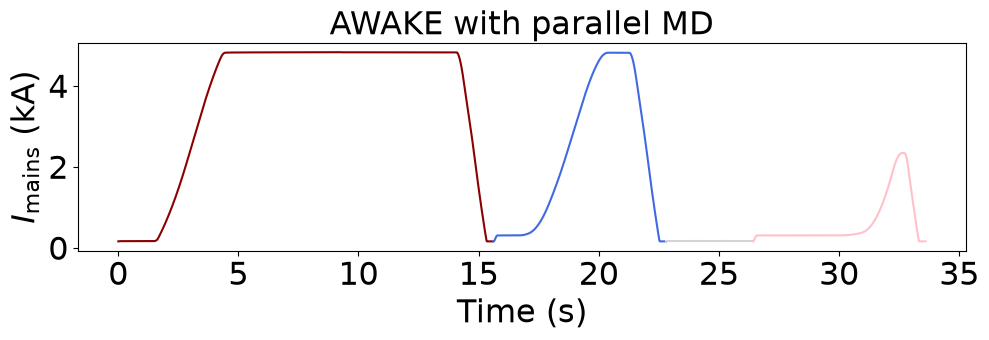

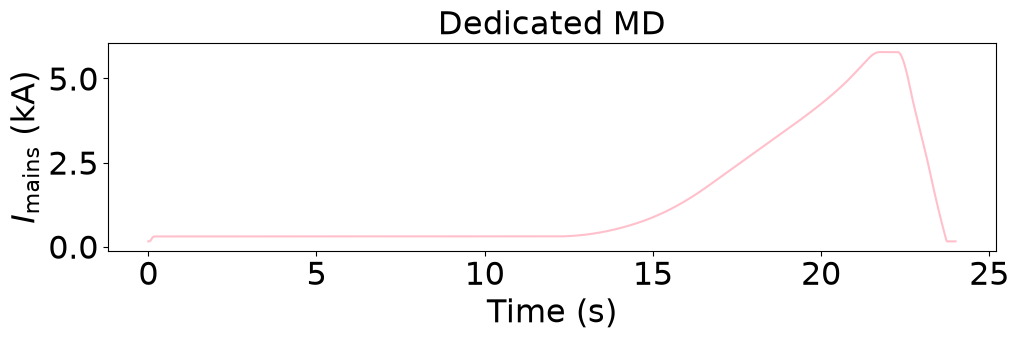

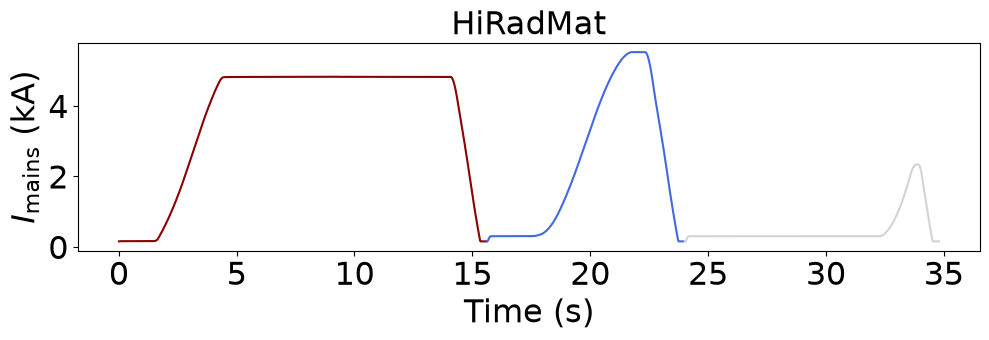

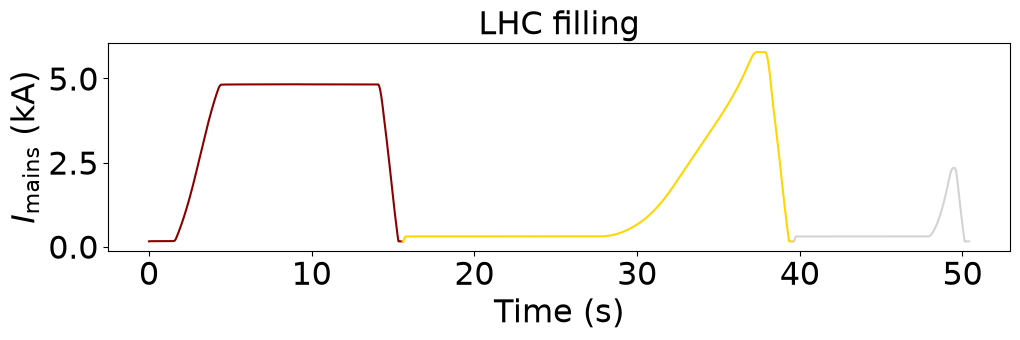

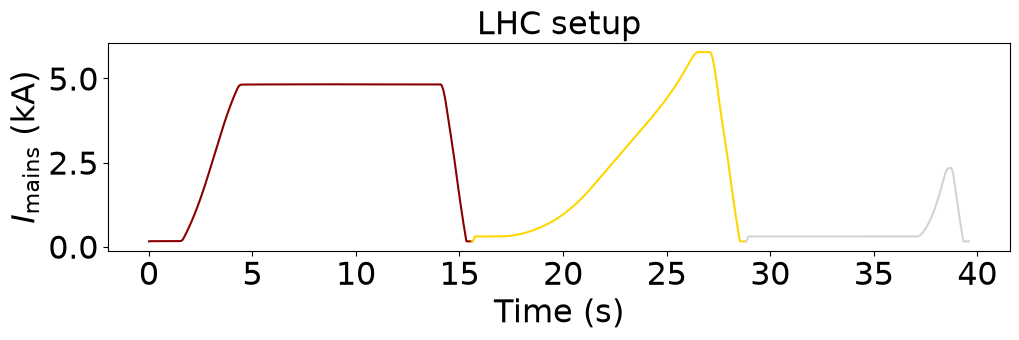

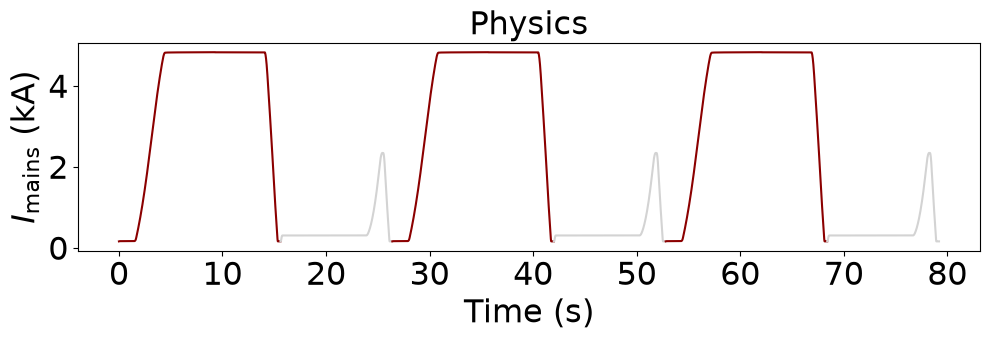

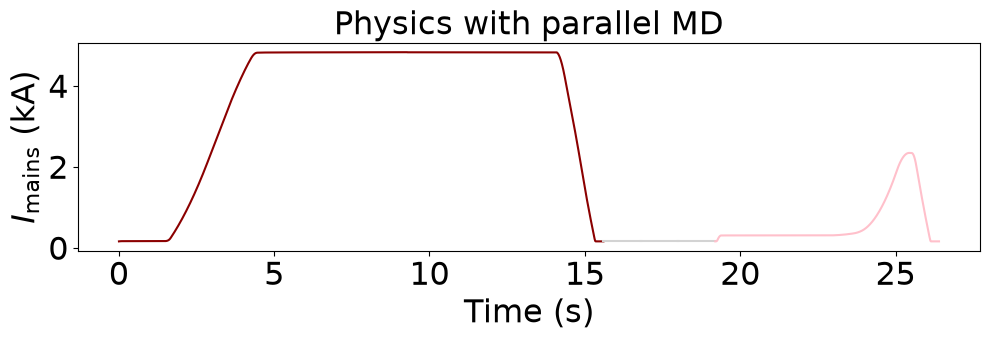

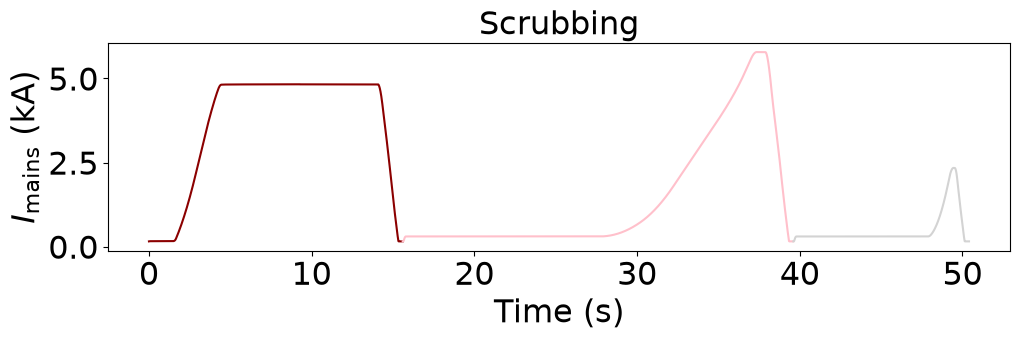

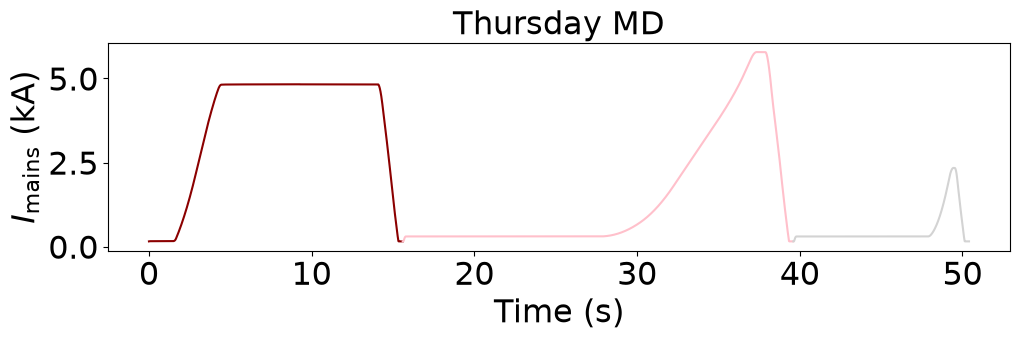

In [13]:
supercycle_table = {
    'AWAKE': AWAKE_SC,
    'AWAKE with parallel MD': AWAKE_parallel_MD_SC,
    'Dedicated MD': Dedicated_MD_SC,
    'HiRadMat': HiRadMat_SC,
    'LHC filling': LHC_filling_SC,
    'LHC setup': LHC_setup_SC,
    'Physics': Physics_SC,
    'Physics with parallel MD': Physics_parallel_MD_SC,
    'Scrubbing': Scrubbing_SC,
    'Thursday MD': Thursday_MD_SC
}

fontsize = 23

for name, sc in supercycle_table.items():
    f, ax = plt.subplots(1, 1, figsize=(10, 3.5))
    ax.set_title(name, fontsize=fontsize)
    ax.set_xlabel('Time (s)', fontsize=fontsize)
    ax.set_ylabel(r'$I_{\mathrm{mains}}$ (kA)', fontsize=fontsize)
    ax.tick_params(axis='both', which='major', labelsize=fontsize)

    s0 = 0
    for cycle in sc.cycles:
        ax.plot(s0 + cycle.cycle_profile_x/1e3, cycle.cycle_profile_y/1e3, color=cycle.color)
        s0 += cycle.cycle_profile_x.values[-1]/1e3

    plt.tight_layout()
    plt.show()